# SWYNEX Task 1 — Data Cleaning & Preparation

**Dataset:** Titanic passenger dataset (891 rows × 12 columns)  
**Tools:** Python, Pandas, NumPy, Matplotlib  
**Objective:** Clean and prepare a raw public dataset for analysis by identifying missing values, duplicate records, data-type issues, inconsistent values, and invalid ranges.

This notebook documents the complete before → cleaning → after workflow.


## 1. Import Libraries

In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)


## 2. Load the Raw Dataset

In [35]:
df = pd.read_csv("../data/raw/titanic_raw.csv")

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Initial Data Inspection

In [36]:
print("Shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nDescriptive statistics:")
display(df.describe(include="all").T)


Shape: (891, 12)

Data types:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Name,str
Sex,str
Age,float64
SibSp,int64
Parch,int64
Ticket,str
Fare,float64



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 4. Identify Missing Values

In [25]:
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)

missing_report = pd.DataFrame({
    "missing_count": missing,
    "missing_percent": missing_pct.round(2)
})
display(missing_report)


,missing_count,missing_percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22
PassengerId,0,0.00
Name,0,0.00
Pclass,0,0.00
Survived,0,0.00
Sex,0,0.00
Parch,0,0.00
SibSp,0,0.00


### Missing-value visualization

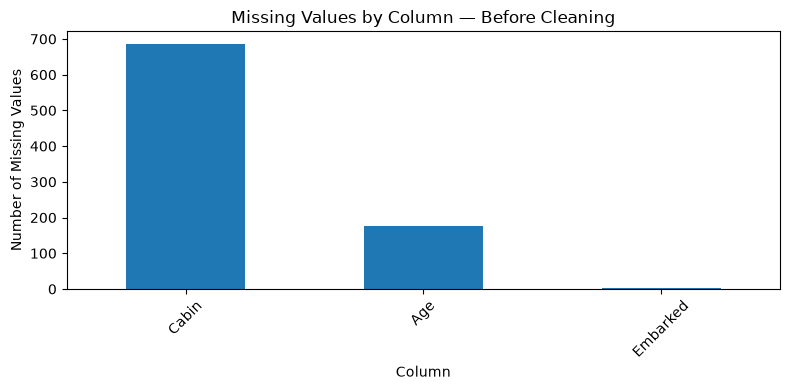

In [26]:
missing_report = missing_report[missing_report["missing_count"] > 0]

plt.figure(figsize=(8, 4))
missing_report["missing_count"].plot(kind="bar")
plt.title("Missing Values by Column — Before Cleaning")
plt.xlabel("Column")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 5. Check Duplicate Records

In [27]:
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


## 6. Check Inconsistent Values

In [28]:
print("Unique Sex values:", df["Sex"].dropna().unique())
print("Unique Embarked values:", df["Embarked"].dropna().unique())

print("\nInvalid Sex values:",
      sorted(set(df["Sex"].dropna()) - {"male", "female"}))

print("Invalid Embarked values:",
      sorted(set(df["Embarked"].dropna()) - {"C", "Q", "S"}))


Unique Sex values: <StringArray>
['male', 'female']
Length: 2, dtype: str
Unique Embarked values: <StringArray>
['S', 'C', 'Q']
Length: 3, dtype: str

Invalid Sex values: []
Invalid Embarked values: []


## 7. Check Invalid Numerical Values and Data Types

In [29]:
expected_numeric = ["PassengerId", "Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]

print("Current dtypes:")
display(df[expected_numeric].dtypes.to_frame("dtype"))

print("Invalid Survived values:", (~df["Survived"].isin([0, 1])).sum())
print("Invalid Pclass values:", (~df["Pclass"].isin([1, 2, 3])).sum())
print("Negative Age values:", (df["Age"] < 0).sum())
print("Negative Fare values:", (df["Fare"] < 0).sum())


Current dtypes:


,dtype
PassengerId,int64
Survived,int64
Pclass,int64
Age,float64
SibSp,int64
Parch,int64
Fare,float64


Invalid Survived values: 0
Invalid Pclass values: 0
Negative Age values: 0
Negative Fare values: 0


## 8. Cleaning Strategy

1. Normalize whitespace and categorical text formatting.
2. Fill missing **Age** using the median within **Pclass + Sex**, with overall median as fallback.
3. Fill missing **Cabin** with `Unknown` because an unrecorded cabin is meaningful information rather than a reason to delete the passenger.
4. Fill missing **Embarked** with the mode.
5. Enforce expected numeric data types.
6. Validate ranges and categories after cleaning.


In [30]:
cleaned = df.copy()

# Text normalization
for col in ["Name", "Sex", "Ticket", "Cabin", "Embarked"]:
    cleaned[col] = cleaned[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

cleaned["Sex"] = cleaned["Sex"].str.lower()
cleaned["Embarked"] = cleaned["Embarked"].str.upper()

# Age imputation
age_group_median = cleaned.groupby(["Pclass", "Sex"])["Age"].transform("median")
cleaned["Age"] = cleaned["Age"].fillna(age_group_median)
cleaned["Age"] = cleaned["Age"].fillna(cleaned["Age"].median())

# Cabin and Embarked imputation
cleaned["Cabin"] = cleaned["Cabin"].fillna("Unknown")
cleaned["Embarked"] = cleaned["Embarked"].fillna(cleaned["Embarked"].mode()[0])

# Data types
cleaned["PassengerId"] = cleaned["PassengerId"].astype("int64")
cleaned["Survived"] = cleaned["Survived"].astype("int64")
cleaned["Pclass"] = cleaned["Pclass"].astype("int64")
cleaned["SibSp"] = cleaned["SibSp"].astype("int64")
cleaned["Parch"] = cleaned["Parch"].astype("int64")
cleaned["Age"] = cleaned["Age"].astype("float64")
cleaned["Fare"] = cleaned["Fare"].astype("float64")

display(cleaned.head())


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,Unknown,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,Unknown,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,Unknown,S


## 9. Before vs After

In [31]:
before_missing = df.isna().sum()
after_missing = cleaned.isna().sum()

comparison = pd.DataFrame({
    "missing_before": before_missing,
    "missing_after": after_missing
})
comparison = comparison[comparison["missing_before"] > 0]
display(comparison)


,missing_before,missing_after
Age,177,0
Cabin,687,0
Embarked,2,0


## 10. Final Validation

In [32]:
checks = {
    "No missing values": cleaned.isna().sum().sum() == 0,
    "No duplicate rows": cleaned.duplicated().sum() == 0,
    "Survived contains only 0/1": cleaned["Survived"].isin([0, 1]).all(),
    "Pclass contains only 1/2/3": cleaned["Pclass"].isin([1, 2, 3]).all(),
    "Age is non-negative": (cleaned["Age"] >= 0).all(),
    "Fare is non-negative": (cleaned["Fare"] >= 0).all(),
    "Sex categories valid": cleaned["Sex"].isin(["male", "female"]).all(),
    "Embarked categories valid": cleaned["Embarked"].isin(["C", "Q", "S"]).all()
}

validation_df = pd.DataFrame({
    "Check": list(checks.keys()),
    "Passed": list(checks.values())
})
display(validation_df)

print("\nFinal shape:", cleaned.shape)
print("Total missing cells:", cleaned.isna().sum().sum())
print("Duplicate rows:", cleaned.duplicated().sum())


,Check,Passed
0,No missing values,True
1,No duplicate rows,True
2,Survived contains only 0/1,True
3,Pclass contains only 1/2/3,True
4,Age is non-negative,True
5,Fare is non-negative,True
6,Sex categories valid,True
7,Embarked categories valid,True



Final shape: (891, 12)
Total missing cells: 0
Duplicate rows: 0


## 11. Save the Cleaned Dataset

In [33]:
cleaned.to_csv("../data/cleaned/titanic_cleaned.csv", index=False)

print("Saved: ../data/cleaned/titanic_cleaned.csv")


Saved: ../data/cleaned/titanic_cleaned.csv


## 12. Conclusion

The raw Titanic dataset was audited and cleaned without deleting valid passenger records. Missing Age values were imputed using group medians, missing Cabin values were represented as `Unknown`, missing Embarked values were filled with the mode, text fields were normalized, expected data types were enforced, and logical range/category checks were completed.

The resulting CSV is ready for downstream analysis or machine-learning preprocessing.
